In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [4]:
df=pd.read_csv(r"C:\Users\ROHAN\Downloads\Sales Datasets\car_prices.csv")
df.head()

,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate
0,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg566472,ca,5.0,16639.0,white,black,kia motors america inc,20500.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
1,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg561319,ca,5.0,9393.0,white,beige,kia motors america inc,20800.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
2,2014,BMW,3 Series,328i SULEV,Sedan,automatic,wba3c1c51ek116351,ca,45.0,1331.0,gray,black,financial services remarketing (lease),31900.0,30000.0,Thu Jan 15 2015 04:30:00 GMT-0800 (PST)
3,2015,Volvo,S60,T5,Sedan,automatic,yv1612tb4f1310987,ca,41.0,14282.0,white,black,volvo na rep/world omni,27500.0,27750.0,Thu Jan 29 2015 04:30:00 GMT-0800 (PST)
4,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,wba6b2c57ed129731,ca,43.0,2641.0,gray,black,financial services remarketing (lease),66000.0,67000.0,Thu Dec 18 2014 12:30:00 GMT-0800 (PST)


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 558837 entries, 0 to 558836
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   year          558837 non-null  int64  
 1   make          548536 non-null  str    
 2   model         548438 non-null  str    
 3   trim          548186 non-null  str    
 4   body          545642 non-null  str    
 5   transmission  493485 non-null  str    
 6   vin           558833 non-null  str    
 7   state         558837 non-null  str    
 8   condition     547017 non-null  float64
 9   odometer      558743 non-null  float64
 10  color         558088 non-null  str    
 11  interior      558088 non-null  str    
 12  seller        558837 non-null  str    
 13  mmr           558799 non-null  float64
 14  sellingprice  558825 non-null  float64
 15  saledate      558825 non-null  str    
dtypes: float64(4), int64(1), str(11)
memory usage: 68.2 MB


In [9]:
df.shape

(558837, 16)

In [12]:
df.describe(include='object')

C:\Users\ROHAN\AppData\Local\Temp\ipykernel_25796\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,make,model,trim,body,transmission,vin,state,color,interior,seller,saledate
count,548536,548438,548186,545642,493485,558833,558837,558088,558088,558837,558825
unique,96,973,1963,87,4,550297,64,46,17,14263,3766
top,Ford,Altima,Base,Sedan,automatic,automatic,fl,black,black,nissan-infiniti lt,Tue Feb 10 2015 01:30:00 GMT-0800 (PST)
freq,93554,19349,55817,199437,475915,22,82945,110970,244329,19693,5334


In [14]:
df.describe()

,year,condition,odometer,mmr,sellingprice
count,558837.000000,547017.000000,558743.000000,558799.000000,558825.000000
mean,2010.038927,30.672365,68320.017767,13769.377495,13611.358810
std,3.966864,13.402832,53398.542821,9679.967174,9749.501628
min,1982.000000,1.000000,1.000000,25.000000,1.000000
25%,2007.000000,23.000000,28371.000000,7100.000000,6900.000000
50%,2012.000000,35.000000,52254.000000,12250.000000,12100.000000
75%,2013.000000,42.000000,99109.000000,18300.000000,18200.000000
max,2015.000000,49.000000,999999.000000,182000.000000,230000.000000


In [43]:
df.isnull().sum()

year            0
make            0
model           0
trim            0
body            0
transmission    0
vin             0
state           0
condition       0
odometer        0
color           0
interior        0
seller          0
mmr             0
sellingprice    0
saledate        0
dtype: int64

In [36]:
df.isnull().sum()

year            0
make            0
model           0
trim            0
body            0
transmission    0
vin             4
state           0
condition       0
odometer        0
color           0
interior        0
seller          0
mmr             0
sellingprice    0
saledate        0
dtype: int64

In [37]:
df['make'].fillna('Unknown')

0            Kia
1            Kia
2            BMW
3          Volvo
4            BMW
           ...  
558832       Kia
558833       Ram
558834       BMW
558835    Nissan
558836      Ford
Name: make, Length: 558825, dtype: str

In [38]:
categerical_cols=['make','model','trim','body','transmission','color','interior']
for col in categerical_cols:
    df[col]=df[col].fillna('Unknown')


In [39]:
numerical_cols=['condition','odometer','mmr']
for col in numerical_cols:
    df[col]=df[col].fillna(df[col].median())

In [40]:
df.dropna(subset=['sellingprice','saledate'],inplace=True)

C:\Users\ROHAN\AppData\Local\Temp\ipykernel_25796\2999360266.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=['sellingprice','saledate'],inplace=True)


In [44]:
df.dropna(subset=['vin'],inplace=True)

C:\Users\ROHAN\AppData\Local\Temp\ipykernel_25796\877875709.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=['vin'],inplace=True)


In [45]:
df.isnull().sum()

year            0
make            0
model           0
trim            0
body            0
transmission    0
vin             0
state           0
condition       0
odometer        0
color           0
interior        0
seller          0
mmr             0
sellingprice    0
saledate        0
dtype: int64

In [47]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (558821, 16)

Column Names:
['year', 'make', 'model', 'trim', 'body', 'transmission', 'vin', 'state', 'condition', 'odometer', 'color', 'interior', 'seller', 'mmr', 'sellingprice', 'saledate']


In [48]:
print("Average Selling Price:", df['sellingprice'].mean())
print("Maximum Selling Price:", df['sellingprice'].max())
print("Minimum Selling Price:", df['sellingprice'].min())

Average Selling Price: 13611.358175515952
Maximum Selling Price: 230000.0
Minimum Selling Price: 1.0


In [49]:
df['make'].value_counts().head(10)

make
Ford         93553
Chevrolet    60197
Nissan       53946
Toyota       39871
Dodge        30708
Honda        27206
Hyundai      21811
BMW          20719
Kia          18075
Chrysler     17274
Name: count, dtype: int64

In [63]:
df['transmission'].value_counts()

transmission
automatic    475904
Unknown       65351
manual        17544
sedan            12
Sedan            10
Name: count, dtype: int64

In [54]:
df['transmission']=df['transmission'].fillna('torque')

In [68]:
print(df['condition'].describe())

count    558821.000000
mean         30.764059
std          13.275023
min           1.000000
25%          24.000000
50%          35.000000
75%          41.000000
max          49.000000
Name: condition, dtype: float64


In [70]:
df.groupby('make')['sellingprice'].mean().sort_values(ascending=False).head(10)

make
Rolls-Royce     153488.235294
Ferrari         127210.526316
Lamborghini     112625.000000
Bentley          74367.672414
airstream        71000.000000
Tesla            67054.347826
Aston Martin     54812.000000
Fisker           46461.111111
Maserati         45320.300752
Lotus            40800.000000
Name: sellingprice, dtype: float64

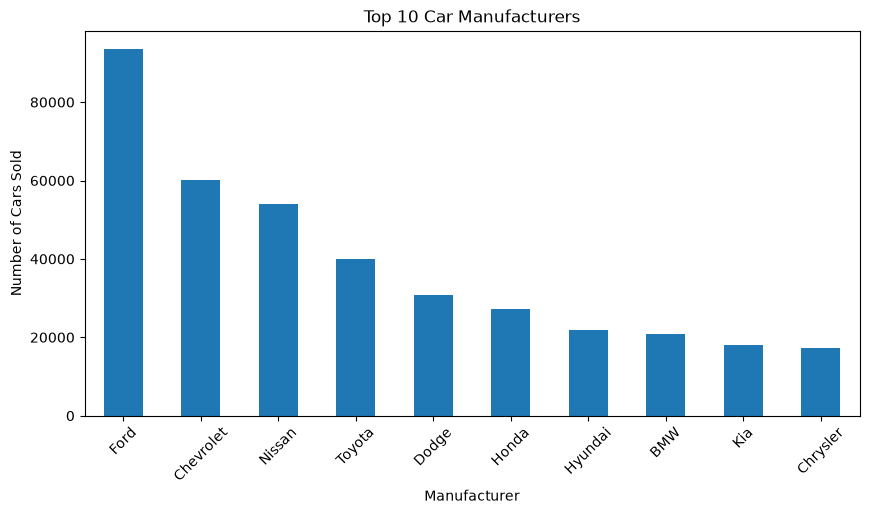

In [88]:
plt.figure(figsize=(10,5))

df['make'].value_counts().head(10).plot(kind='bar')

plt.title('Top 10 Car Manufacturers')
plt.xlabel('Manufacturer')
plt.ylabel('Number of Cars Sold')
plt.xticks(rotation=45)
plt.show()

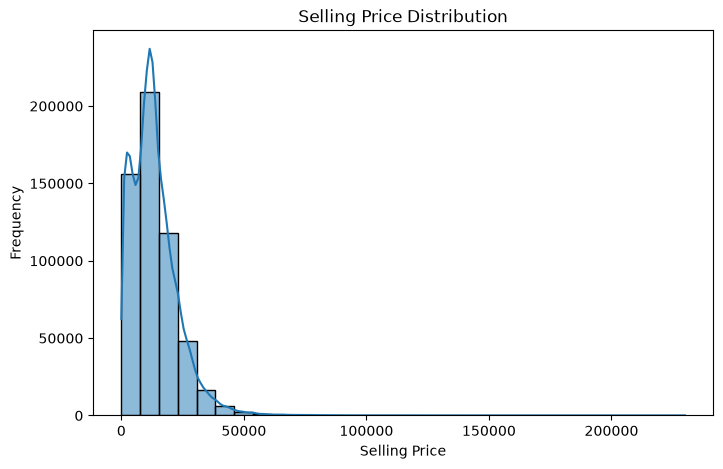

In [73]:
plt.figure(figsize=(8,5))

sns.histplot(df['sellingprice'], bins=30, kde=True)

plt.title('Selling Price Distribution')
plt.xlabel('Selling Price')
plt.ylabel('Frequency')
plt.show()

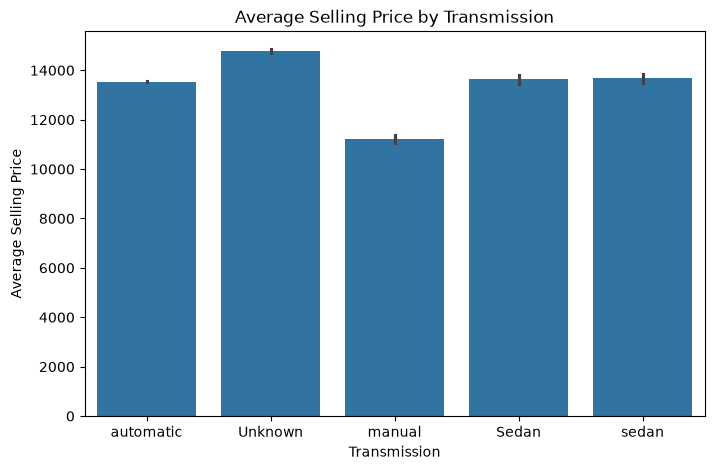

In [74]:
plt.figure(figsize=(8,5))

sns.barplot(data=df, x='transmission', y='sellingprice')

plt.title('Average Selling Price by Transmission')
plt.xlabel('Transmission')
plt.ylabel('Average Selling Price')
plt.show()

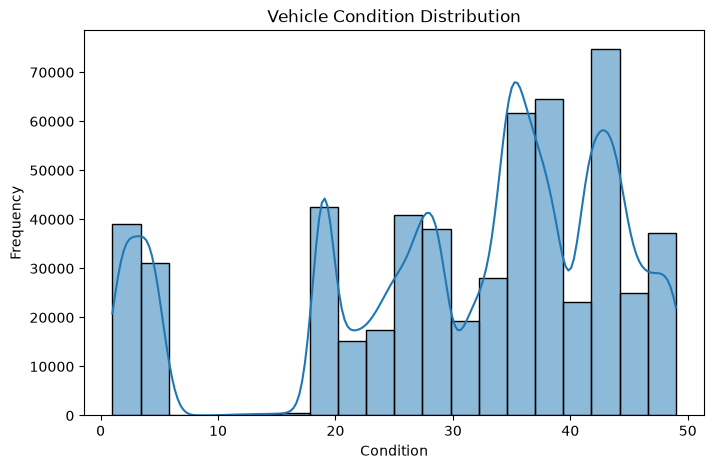

In [75]:
plt.figure(figsize=(8,5))

sns.histplot(df['condition'], bins=20, kde=True)

plt.title('Vehicle Condition Distribution')
plt.xlabel('Condition')
plt.ylabel('Frequency')
plt.show()

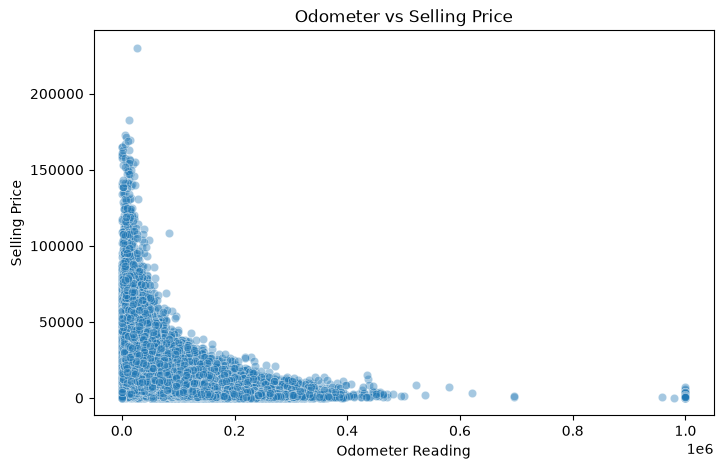

In [78]:
plt.figure(figsize=(8,5))

sns.scatterplot(data=df, x='odometer', y='sellingprice', alpha=0.4)

plt.title('Odometer vs Selling Price')
plt.xlabel('Odometer Reading')
plt.ylabel('Selling Price')
plt.legend
plt.show()

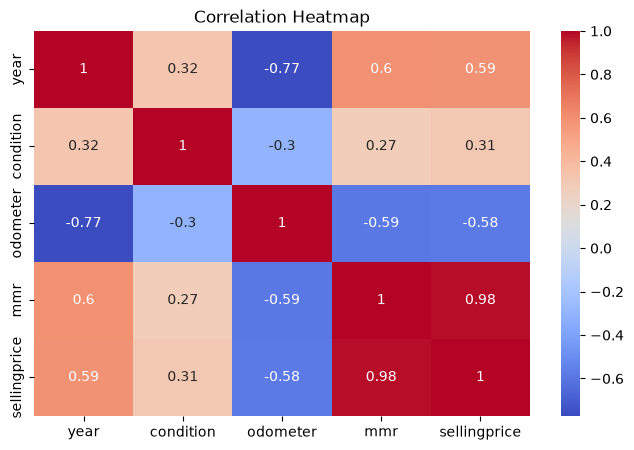

In [79]:
plt.figure(figsize=(8,5))

sns.heatmap(
    df[['year', 'condition', 'odometer', 'mmr', 'sellingprice']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')
plt.show()

In [89]:
print("Mean:", df['sellingprice'].mean())
print("Median:", df['sellingprice'].median())
print("Mode:", df['sellingprice'].mode()[0])

Mean: 13611.358175515952
Median: 12100.0
Mode: 11000.0


In [91]:
print("Variance:", df['sellingprice'].var())
print("Standard Deviation:", df['sellingprice'].std())

Variance: 95053461.30576396
Standard Deviation: 9749.53646620002


In [93]:
print(df['sellingprice'].quantile([0.25, 0.50, 0.75]))

0.25     6900.0
0.50    12100.0
0.75    18200.0
Name: sellingprice, dtype: float64


In [95]:
correlation = df[
    ['year', 'condition', 'odometer', 'mmr', 'sellingprice']
].corr()

print(correlation)

                  year  condition  odometer       mmr  sellingprice
year          1.000000   0.323579 -0.772410  0.596605      0.586484
condition     0.323579   1.000000 -0.304591  0.273153      0.313121
odometer     -0.772410  -0.304591  1.000000 -0.587967     -0.582274
mmr           0.596605   0.273153 -0.587967  1.000000      0.983634
sellingprice  0.586484   0.313121 -0.582274  0.983634      1.000000


In [96]:
Q1 = df['sellingprice'].quantile(0.25)
Q3 = df['sellingprice'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df['sellingprice'] < lower) |
    (df['sellingprice'] > upper)
]

print("Number of outliers:", len(outliers))

Number of outliers: 16354


In [98]:
summary = df['sellingprice'].describe()

print(summary)

count    558821.000000
mean      13611.358176
std        9749.536466
min           1.000000
25%        6900.000000
50%       12100.000000
75%       18200.000000
max      230000.000000
Name: sellingprice, dtype: float64


In [99]:
df.to_csv(r'C:\Users\ROHAN\OneDrive\Desktop\Cynaris_Internship folder\Week4_Internship\End To End Project\cleaned_sales_data.csv', index=False)